In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Models strictly from Unit II and Unit III
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# Load dataset
df = pd.read_csv("water_quality_of_river_ganga-2014.csv", encoding_errors="ignore")
print("Initial Shape:", df.shape)
df.head(3)

Initial Shape: (64, 27)


,STATION CODE,LOCATIONS,STATE,TEMPERATURE C : Min,TEMPERATURE C : Max,TEMPERATURE C : Mean,D.O. (mg/l) : Min : > 4 mg/l,D.O. (mg/l) : Max : > 4 mg/l,D.O. (mg/l) : Mean : > 4 mg/l,pH : Min : 6.5-8.5,...,B.O.D. (mg/l) : Mean : < 3 mg/l,NITRATE- N+ NITRITE-N (mg/l) : Min,NITRATE- N+ NITRITE-N (mg/l) : Max,NITRATE- N+ NITRITE-N (mg/l) : Mean,FECAL COLIFORM (MPN/100ml) : Min : < 2500 MPN/100ml,FECAL COLIFORM (MPN/100ml) : Max : < 2500 MPN/100ml,FECAL COLIFORM (MPN/100ml) : Mean : < 2500 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Min : < 5000 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Max : < 5000 MPN/100ml,TOTAL COLIFORM (MPN/100ml) : Mean : < 5000 MPN/100ml
0,1484,"ALKANANDA B/C MANDAKINI AT RUDRA PRAYAG, UTTAR...",UTTARAKHAND,16.0,19.0,17.5,7.8,9.2,8.5,8.0,...,0.7,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,1485,"MANDAKINI B/C ALKALNADA AT RUDRAPRAYAG, UTTAR ...",UTTARAKHAND,15.0,18.0,16.3,8.6,9.0,8.8,8.0,...,0.7,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,1486,"ALKANANDA A/C MANDAKINI AT RUDRAPRAYAG, UTTAR ...",UTTARAKHAND,15.0,19.0,16.7,7.4,8.4,8.1,7.8,...,1.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df.columns = df.columns.str.strip().str.replace('\n', ' ').str.replace('  ', ' ')

df = df.drop_duplicates()

df = df.replace(['-', 'NA', 'NAN', 'N/A', 'nil', 'Nil', ' '], np.nan)

meta_cols = ['STATION CODE', 'LOCATIONS', 'STATE']
feature_cols = [c for c in df.columns if c not in meta_cols]

for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df[col] = df[col].fillna(df[col].median())

do_mean_col = [c for c in df.columns if 'D.O.' in c and 'Mean' in c][0]
bod_mean_col = [c for c in df.columns if 'B.O.D.' in c and 'Mean' in c][0]

df['Potable'] = ((df[do_mean_col] >= 5.0) & (df[bod_mean_col] <= 3.0)).astype(int)

print(df['Potable'].value_counts())
print(df[feature_cols].isnull().sum().sum())

Potable
1    42
0    22
Name: count, dtype: int64
0


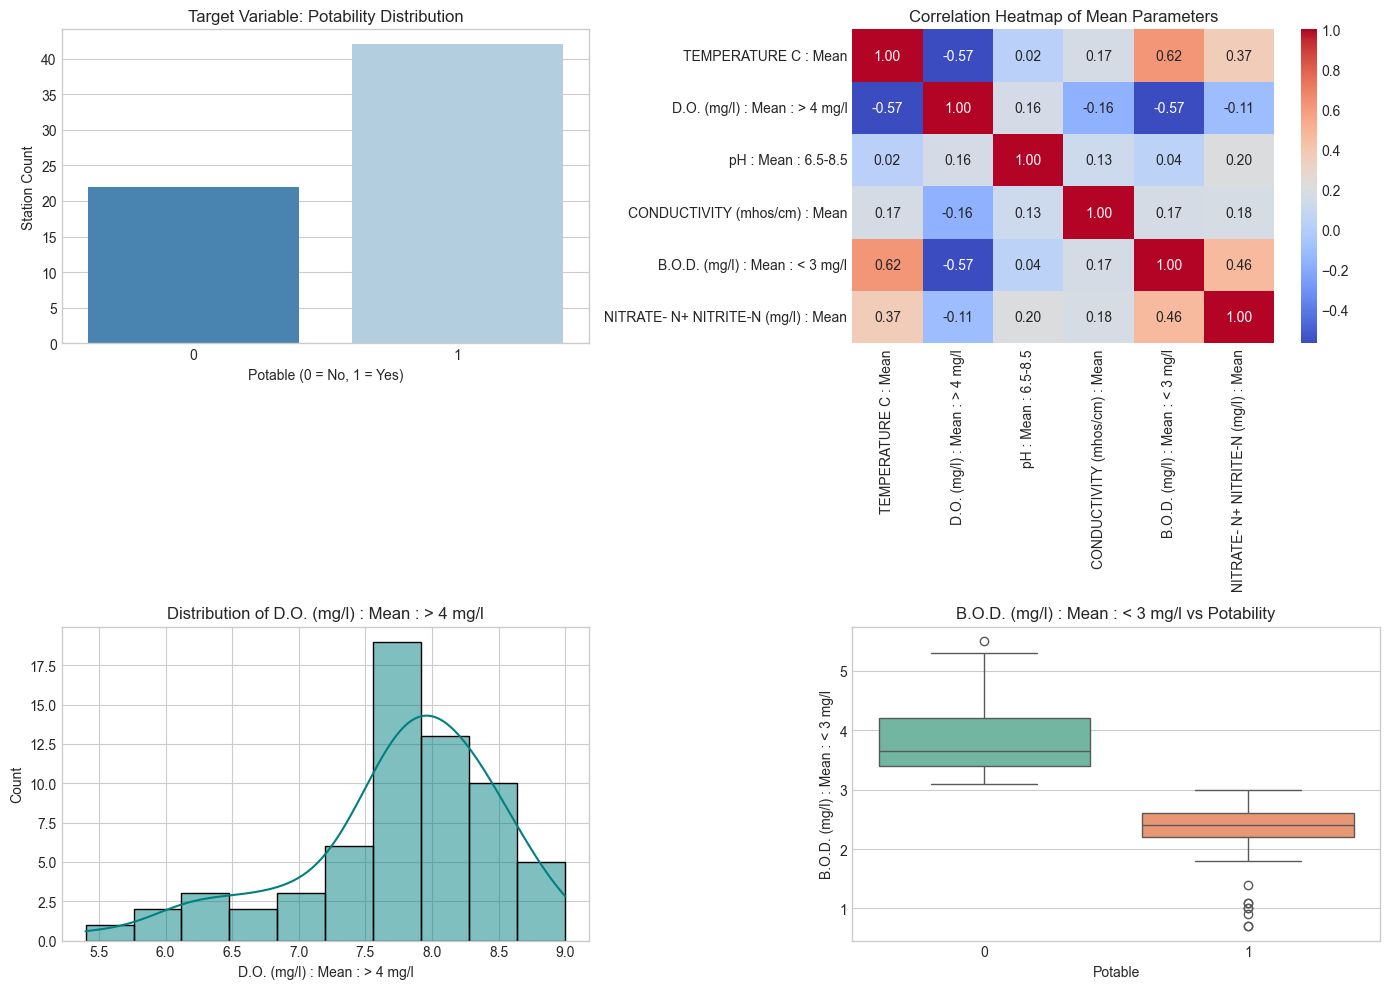

In [9]:
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
sns.countplot(x='Potable', data=df, palette='Blues_r')
plt.title('Target Variable: Potability Distribution')
plt.xlabel('Potable (0 = No, 1 = Yes)')
plt.ylabel('Station Count')

plt.subplot(2, 2, 2)
corr_cols = [c for c in feature_cols if 'Mean' in c][:6]
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Mean Parameters')

plt.subplot(2, 2, 3)
sns.histplot(df[do_mean_col], kde=True, color='teal')
plt.title(f'Distribution of {do_mean_col}')

plt.subplot(2, 2, 4)
sns.boxplot(x='Potable', y=bod_mean_col, data=df, palette='Set2')
plt.title(f'{bod_mean_col} vs Potability')

plt.tight_layout()
plt.show()

In [10]:
X = df[[c for c in feature_cols if c not in [do_mean_col, bod_mean_col]]]
y = df['Potable']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=3),
    "Naïve Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1 Score": round(f1_score(y_test, y_pred, zero_division=0), 4)
    })

comparison_df = pd.DataFrame(results).sort_values(by="F1 Score", ascending=False).reset_index(drop=True)
comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,100.0,1.0000,1.0,1.0000
1,Naïve Bayes,100.0,1.0000,1.0,1.0000
2,Decision Tree,100.0,1.0000,1.0,1.0000
3,Support Vector Machine,100.0,1.0000,1.0,1.0000
4,K-Nearest Neighbors,87.5,0.8333,1.0,0.9091


Best Model: Logistic Regression

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00        10

    accuracy                           1.00        16
   macro avg       1.00      1.00      1.00        16
weighted avg       1.00      1.00      1.00        16



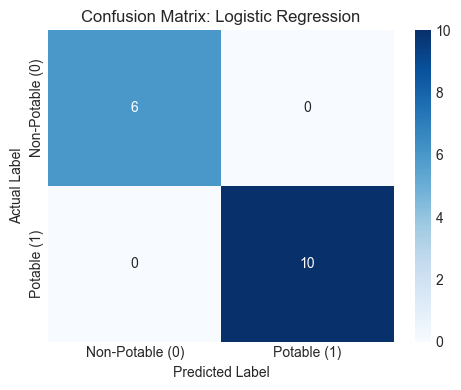

In [12]:
best_model_name = comparison_df.iloc[0]['Model']
best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test_scaled)

print(f"Best Model: {best_model_name}\n")
print(classification_report(y_test, y_pred_best))

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Non-Potable (0)', 'Potable (1)'], 
            yticklabels=['Non-Potable (0)', 'Potable (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title(f'Confusion Matrix: {best_model_name}')
plt.tight_layout()
plt.show()

In [13]:
predictions_table = pd.DataFrame({
    'Actual_Status': y_test.values,
    'Predicted_Status': y_pred_best,
    'Result': ['Correct' if a == p else 'Incorrect' for a, p in zip(y_test.values, y_pred_best)]
})
predictions_table['Actual_Label'] = predictions_table['Actual_Status'].map({1: 'Potable', 0: 'Non-Potable'})
predictions_table['Predicted_Label'] = predictions_table['Predicted_Status'].map({1: 'Potable', 0: 'Non-Potable'})

print(predictions_table[['Actual_Label', 'Predicted_Label', 'Result']])

   Actual_Label Predicted_Label   Result
0   Non-Potable     Non-Potable  Correct
1   Non-Potable     Non-Potable  Correct
2       Potable         Potable  Correct
3       Potable         Potable  Correct
4       Potable         Potable  Correct
5   Non-Potable     Non-Potable  Correct
6       Potable         Potable  Correct
7       Potable         Potable  Correct
8   Non-Potable     Non-Potable  Correct
9       Potable         Potable  Correct
10  Non-Potable     Non-Potable  Correct
11  Non-Potable     Non-Potable  Correct
12      Potable         Potable  Correct
13      Potable         Potable  Correct
14      Potable         Potable  Correct
15      Potable         Potable  Correct
